# Summary stats for datasets

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import os
import glob
from scipy.stats import entropy

In [2]:
def entropy_from_keys(adata, keys):
    if not keys:
        return None
    
    if len(keys) == 1:
        s = adata.obs[keys[0]].astype(str)
    else:
        s = adata.obs[keys].astype(str).agg("_".join, axis=1)

    counts = s.value_counts(normalize=True)
    return entropy(counts)

def rare_abundant(adata, keys):
    if not keys:
        return None
    
    if len(keys) == 1:
        s = adata.obs[keys[0]].astype(str)
    else:
        s = adata.obs[keys].astype(str).agg("_".join, axis=1)

    counts = s.value_counts(normalize=True)
    return np.sum(counts <= 0.01), np.sum(counts >= 0.3)

def pseudobulk_corr(adata, keys):
    if not keys:
        return None
    
    if len(keys) == 1:
        s = adata.obs[keys[0]].astype(str)
    else:
        s = adata.obs[keys].astype(str).agg("_".join, axis=1)

    adata.obs['pseudobulk_key'] = s
    agg = sc.get.aggregate(adata, 'pseudobulk_key', 'sum', layer='counts')
    agg.X = agg.layers['sum']
    sc.pp.normalize_total(agg)
    sc.pp.log1p(agg)
    coeff = np.corrcoef(agg.X)
    vals =  coeff[np.triu_indices(coeff.shape[0], k=1)]
    return vals.mean()

def mean_umi(adata, keys):
    if not keys:
        return None
    
    if len(keys) == 1:
        s = adata.obs[keys[0]].astype(str)
    else:
        s = adata.obs[keys].astype(str).agg("_".join, axis=1)

    adata.obs['pseudobulk_key'] = s
    agg = sc.get.aggregate(adata, 'pseudobulk_key', 'mean', layer='counts')
    return agg.layers['mean'].sum(1)

def gini(x):
    mad = np.abs(np.subtract.outer(x, x)).mean()
    rmad = mad/np.mean(x)
    g = 0.5 * rmad
    return g

def batch_specific_cell_type(adata, label_key, batch_key):
    n_batches = adata.obs[batch_key].nunique()
    ct_batch = adata.obs.groupby(label_key)[batch_key].nunique()
    cts = ct_batch[ct_batch < n_batches].index
    return len(adata.obs[adata.obs[label_key].isin(cts)]) / adata.n_obs

def num_batch_specific_cell_types(adata, label_key, batch_key):
    unique_counts = adata.obs.groupby(label_key)[batch_key].nunique()

    return (unique_counts == 1).sum()

## Transcriptomics data

In [23]:
paths = [
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/human_pancreas_full.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/human_dkd.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/immune_cell_atlas.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/gtex_v9.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/tabula_sapiens.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/snpatho_liver.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/villani_dcs.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/haniffa_covid_2samples.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/haniffa_covid_imbalance.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/pan_cancer_t.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/human_kidney.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/human_liver.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/human_bipolar.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/mouse_hsc_prog.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/mouse_intestine.h5ad",
    "/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/mouse_pancreatic_islet.h5ad"
]

In [24]:
dataset_keys = {
    "scib_sim1": {
        "celltype_keys": ["Group"],
        "batch_keys": ["Batch"]
    },

    "scib_sim2": {
        "celltype_keys": ["Group"],
        "batch_keys": ["Batch"]
    },

    "human_pancreas": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["tech"]
    },

    "human_lung": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    },

    "neurips_bmmc": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    },

    "seurat_pbmc": {
        "celltype_keys": ["celltype.l2"],
        "batch_keys": ["donor"]
    },

    "human_brain_cell_atlas": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["donor_id", "ROIGroup"]
    },

    "human_fetal_gut": {
        "celltype_keys": ["cell_name_detailed"],
        "batch_keys": ["Donor_id", "Organ", "Sample"]
    },

    "human_liver_time": {
        "celltype_keys": ["time"],
        "batch_keys": ["batch"]
    },

    "pan_cancer_dc": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["dataset_id", "cancer_type"]
    },

    "human_eoe": {
        "celltype_keys": ["cell_type_anno"],
        "batch_keys": ["donor_id"]
    },

    "pan_cancer_b": {
        "celltype_keys": ["clusters"],
        "batch_keys": ["study"]
    },

    "human_retina_organoid_tissue": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["sample_id", "tissue"]
    },

    "mouse_regulatory_T": {
        "celltype_keys": ["cell.type"],
        "batch_keys": ["method", "orig.ident"]
    },

    "human_adipose": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["technology", "individual"]
    },

    "tian_multitech": {
        "celltype_keys": ["cell_line"],
        "batch_keys": ["tech"]
    },

    "nph_liver": {
        "celltype_keys": ["Celltype"],
        "batch_keys": ["Sample"]
    },

    "nph_cerebellum": {
        "celltype_keys": ["Celltype"],
        "batch_keys": ["Sample"]
    },

    "tabula_muris_lung": {
        "celltype_keys": ["cell_ontology_id"],
        "batch_keys": ["mouse.id", "tech"]
    },

    "human_pbmc_sequencing_techs": {
        "celltype_keys": ["CellType"],
        "batch_keys": ["Method", "Experiment"]
    },

    "mouse_retina": {
        "celltype_keys": ["CellType"],
        "batch_keys": ["dataset"]
    },

    "mouse_mammary": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["BATCH"]
    },

    "macaque_retina": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["BATCH"]
    },

    "human_heart": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["DonorID", "Tissue"]
    },
    
    "mouse_cortex_sequencing_techs": {
        "celltype_keys": ["CellType"],
        "batch_keys": ["Method", "Experiment"]
    },
    "jurkat_293t": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["dataset"]
    },
    "3_5_pbmc": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["batch"]
    },
    "cellranger_versions": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    },
    "human_pancreas_full": {
        "batch_keys": ["tech"],
        "celltype_keys": ["celltype"],
    },
    "human_dkd": {
        "batch_keys": ["batch", "assay"],  # Main batch column first
        "celltype_keys": ["cell_type"],
    },
    "immune_cell_atlas": {
        "batch_keys": ["batch", "assay"],
        "celltype_keys": ["cell_type"],
    },
    "gtex_v9": {
        "batch_keys": ["batch"],
        "celltype_keys": ["cell_type"],
    },
    "tabula_sapiens": {
        "batch_keys": ["batch", "assay"],
        "celltype_keys": ["cell_type"],
    },
    "snpatho_liver": {
        "batch_keys": ["sample_id", "processing_method"],
        "celltype_keys": ["major_annotation"],
    },
    "villani_dcs": {
        "batch_keys": ["batch"],
        "celltype_keys": ["cell_type"],
    },
    "haniffa_covid_2samples": {
        "batch_keys": ["sample_id"],
        "celltype_keys": ["initial_clustering"],
    },
    "haniffa_covid_imbalance": {
        "batch_keys": ["sample_id"],
        "celltype_keys": ["initial_clustering"],
    },
    "pan_cancer_t": {
        "batch_keys": ["patient", "cancerType", "platform"],
        "celltype_keys": ["meta_cluster"],
    },
    "human_kidney": {
        "batch_keys": ["donor_id", "suspension_type"],
        "celltype_keys": ["cell_type"],
    },
    "human_liver": {
        "batch_keys": ["donor_id"],
        "celltype_keys": ["cell_type"],
    },
    "human_bipolar": {
        "batch_keys": ["donor_id", "assay"],
        "celltype_keys": ["cell_type"],
    },
    "mouse_pancreatic_islet": {
        "batch_keys": ["batch", "disease", "assay"],
        "celltype_keys": ["cell_type"]
    },
    "mouse_hsc_prog": {
        "batch_keys": ["tech"],
        "celltype_keys": ["CellType"]
    },
    "mouse_intestine": {
        "batch_keys": ["sample_name", "condition", "location"],
        "celltype_keys": ["cell_type"]
    }
}

In [25]:
rows = []

for path in paths:
    adata = sc.read_h5ad(path)
    name = os.path.splitext(os.path.basename(path))[0]
    if name.startswith('desim') or name.startswith('epitome') or name == 'neurips_bmmc_safe':
        continue
    print(name)
    celltype_keys = dataset_keys[name]["celltype_keys"]
    batch_keys    = dataset_keys[name]["batch_keys"]


    ct_key = celltype_keys[0]
    bt_key = batch_keys[0]

    n_cells = adata.n_obs
    n_genes = adata.n_vars
    n_celltypes = adata.obs[ct_key].nunique() if ct_key else None
    n_batches   = adata.obs[bt_key].nunique() if bt_key else None
    
    ent_ct = entropy_from_keys(adata, [ct_key])
    ent_bt = entropy_from_keys(adata, [bt_key])
    rare, abun = rare_abundant(adata, [ct_key])
    umi = mean_umi(adata, [bt_key])
    c = pseudobulk_corr(adata, [ct_key])
    b = pseudobulk_corr(adata, [bt_key])
    
    gini_ct = gini(adata.obs[ct_key].value_counts().to_numpy())
    gini_bt = gini(adata.obs[bt_key].value_counts().to_numpy())
    
    ct_batch_specific = batch_specific_cell_type(adata, ct_key, bt_key)
    num_batch_specific = num_batch_specific_cell_types(adata, ct_key, bt_key)

    rows.append({
        "Dataset": path,
        "Cell count": n_cells,
        "Number of cell types": n_celltypes,
        "Number of batches": n_batches,
        "Number of genes": n_genes,
        "Celltype keys": celltype_keys,
        "Batch keys": batch_keys,
        "Entropy_celltypes": ent_ct,
        "Entropy_batches": ent_bt,
        "Rare cell types": rare,
        "Abundant cell types": abun,
        "UMIs per batch": umi,
        "Celltype correlation": c,
        "Batch correlation": b,
        'Celltype Gini': gini_ct,
        'Batch Gini': gini_bt,
        'Batch-specific cell type proportion': ct_batch_specific,
        'Num batch specific cell types': num_batch_specific
    })

summary = pd.DataFrame(rows)
summary

human_pancreas_full


/tmp/ipykernel_3116157/1443714161.py:71: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_batch = adata.obs.groupby(label_key)[batch_key].nunique()
/tmp/ipykernel_3116157/1443714161.py:96: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unique_counts = adata.obs.groupby(label_key)[batch_key].nunique()


human_dkd


/tmp/ipykernel_3116157/1443714161.py:71: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_batch = adata.obs.groupby(label_key)[batch_key].nunique()
/tmp/ipykernel_3116157/1443714161.py:96: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unique_counts = adata.obs.groupby(label_key)[batch_key].nunique()


immune_cell_atlas


...

mouse_intestine


/tmp/ipykernel_3116157/1443714161.py:71: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_batch = adata.obs.groupby(label_key)[batch_key].nunique()
/tmp/ipykernel_3116157/1443714161.py:96: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unique_counts = adata.obs.groupby(label_key)[batch_key].nunique()


mouse_pancreatic_islet


/tmp/ipykernel_3116157/1443714161.py:71: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_batch = adata.obs.groupby(label_key)[batch_key].nunique()
/tmp/ipykernel_3116157/1443714161.py:96: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unique_counts = adata.obs.groupby(label_key)[batch_key].nunique()


,Dataset,Cell count,Number of cell types,Number of batches,Number of genes,Celltype keys,Batch keys,Entropy_celltypes,Entropy_batches,Rare cell types,Abundant cell types,UMIs per batch,Celltype correlation,Batch correlation,Celltype Gini,Batch Gini,Batch-specific cell type proportion,Num batch specific cell types
0,/ubc/cs/research/beaver/projects/Single-cell-i...,39944,14,30,15149,[celltype],[tech],1.715927,3.158769,5,2,"[11715.498849252013, 11521.40594059406, 9551.4...",0.673580,0.798413,0.695806,0.379737,0.281820,0
1,/ubc/cs/research/beaver/projects/Single-cell-i...,39176,13,11,27980,[cell_type],"[batch, assay]",1.962243,2.266471,3,0,"[8441.887378640777, 2574.8934169278996, 3887.5...",0.898507,0.959956,0.584844,0.266559,0.000000,0
2,/ubc/cs/research/beaver/projects/Single-cell-i...,329762,35,12,29335,[cell_type],"[batch, assay]",3.059231,2.108143,13,0,"[3680.433649698015, 5001.691967644846, 4801.88...",0.887729,0.952736,0.536536,0.463534,0.010216,0
3,/ubc/cs/research/beaver/projects/Single-cell-i...,209126,53,16,28094,[cell_type],[batch],3.169179,2.332904,31,0,"[2106.101829753381, 1864.2444240055186, 1283.9...",0.785295,0.847256,0.664260,0.494784,0.900142,2
4,/ubc/cs/research/beaver/projects/Single-cell-i...,483152,160,29,55904,[cell_type],"[batch, assay]",4.028245,2.310502,129,0,"[17229.53985334195, 859923.4770713913, 11712.5...",0.781509,0.846348,0.737432,0.736809,1.000000,23
5,/ubc/cs/research/beaver/projects/Single-cell-i...,50391,11,6,30171,[major_annotation],"[sample_id, processing_method]",1.221081,1.762489,4,1,"[2787.987474837844, 5234.42366037324, 7430.221...",0.898939,0.835656,0.750174,0.115672,0.026850,0
6,/ubc/cs/research/beaver/projects/Single-cell-i...,768,4,2,17204,[cell_type],[batch],1.386294,0.693147,0,0,"[999639.5729166666, 999543.8125]",0.814584,0.933357,0.000000,0.000000,0.000000,0
7,/ubc/cs/research/beaver/projects/Single-cell-i...,28403,18,2,24737,[initial_clustering],[sample_id],1.765506,0.693114,11,1,"[3130.292914951015, 2778.1141300551794]",0.881336,0.968173,0.739247,0.004066,0.005880,1
8,/ubc/cs/research/beaver/projects/Single-cell-i...,20411,18,10,24737,[initial_clustering],[sample_id],2.092520,1.248700,8,0,"[5760.647979139504, 5480.439001848429, 8664.49...",0.873486,0.954978,0.652064,0.650341,0.071530,1
9,/ubc/cs/research/beaver/projects/Single-cell-i...,172181,41,45,11616,[meta_cluster],"[patient, cancerType, platform]",3.194755,3.583564,19,0,"[4364.28513435144, 5431.95919303072, 933176.83...",0.839430,0.925776,0.550798,0.361873,0.593956,0


In [26]:
summary = summary.set_index('Dataset')

In [27]:
summary.index = summary.index.str.split('/').str[-1].str.split('.').str[0]

In [28]:
summary

,Cell count,Number of cell types,Number of batches,Number of genes,Celltype keys,Batch keys,Entropy_celltypes,Entropy_batches,Rare cell types,Abundant cell types,UMIs per batch,Celltype correlation,Batch correlation,Celltype Gini,Batch Gini,Batch-specific cell type proportion,Num batch specific cell types
Dataset,,,,,,,,,,,,,,,,,
human_pancreas_full,39944,14,30,15149,[celltype],[tech],1.715927,3.158769,5,2,"[11715.498849252013, 11521.40594059406, 9551.4...",0.673580,0.798413,0.695806,0.379737,0.281820,0
human_dkd,39176,13,11,27980,[cell_type],"[batch, assay]",1.962243,2.266471,3,0,"[8441.887378640777, 2574.8934169278996, 3887.5...",0.898507,0.959956,0.584844,0.266559,0.000000,0
immune_cell_atlas,329762,35,12,29335,[cell_type],"[batch, assay]",3.059231,2.108143,13,0,"[3680.433649698015, 5001.691967644846, 4801.88...",0.887729,0.952736,0.536536,0.463534,0.010216,0
gtex_v9,209126,53,16,28094,[cell_type],[batch],3.169179,2.332904,31,0,"[2106.101829753381, 1864.2444240055186, 1283.9...",0.785295,0.847256,0.664260,0.494784,0.900142,2
tabula_sapiens,483152,160,29,55904,[cell_type],"[batch, assay]",4.028245,2.310502,129,0,"[17229.53985334195, 859923.4770713913, 11712.5...",0.781509,0.846348,0.737432,0.736809,1.000000,23
snpatho_liver,50391,11,6,30171,[major_annotation],"[sample_id, processing_method]",1.221081,1.762489,4,1,"[2787.987474837844, 5234.42366037324, 7430.221...",0.898939,0.835656,0.750174,0.115672,0.026850,0
villani_dcs,768,4,2,17204,[cell_type],[batch],1.386294,0.693147,0,0,"[999639.5729166666, 999543.8125]",0.814584,0.933357,0.000000,0.000000,0.000000,0
haniffa_covid_2samples,28403,18,2,24737,[initial_clustering],[sample_id],1.765506,0.693114,11,1,"[3130.292914951015, 2778.1141300551794]",0.881336,0.968173,0.739247,0.004066,0.005880,1
haniffa_covid_imbalance,20411,18,10,24737,[initial_clustering],[sample_id],2.092520,1.248700,8,0,"[5760.647979139504, 5480.439001848429, 8664.49...",0.873486,0.954978,0.652064,0.650341,0.071530,1


In [29]:
summary.to_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/spreadsheets/dataset_final_summary.csv')

In [10]:
summary = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/spreadsheets/dataset_summary.csv')

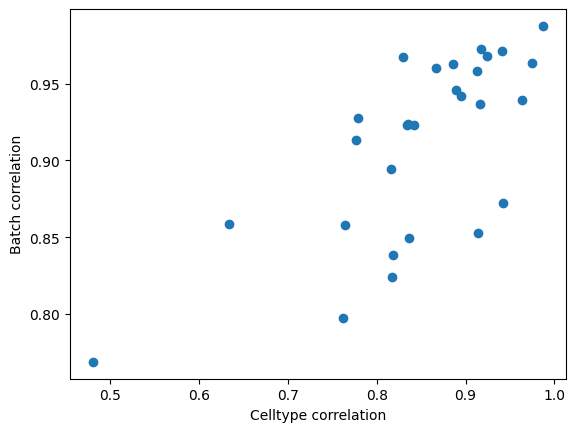

In [11]:
plt.scatter(summary['Celltype correlation'], summary['Batch correlation'])
plt.xlabel("Celltype correlation")
plt.ylabel("Batch correlation")
plt.show()

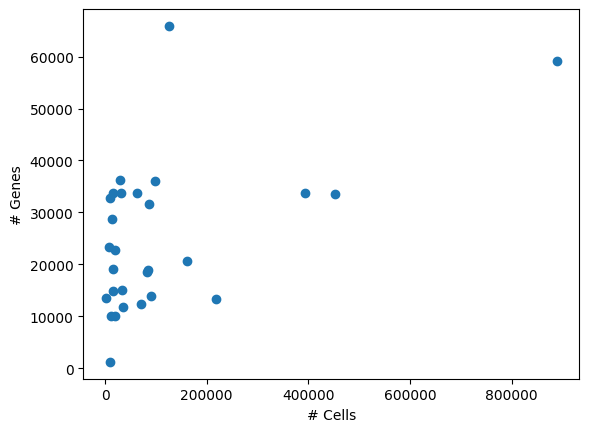

In [12]:
plt.scatter(summary['Cell count'], summary['Number of genes'])
plt.xlabel("# Cells")
plt.ylabel("# Genes")
plt.show()

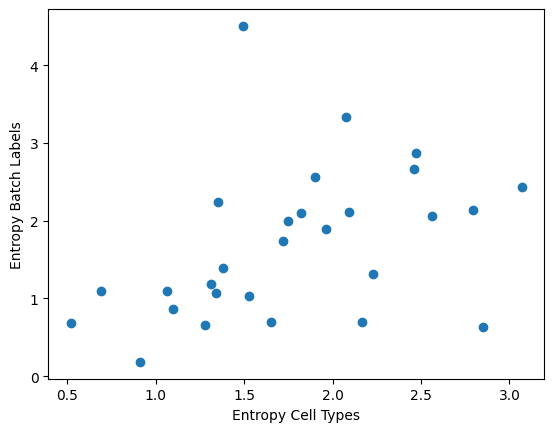

In [13]:
plt.scatter(summary['Entropy_celltypes'], summary['Entropy_batches'])
plt.xlabel("Entropy Cell Types")
plt.ylabel("Entropy Batch Labels")
plt.show()

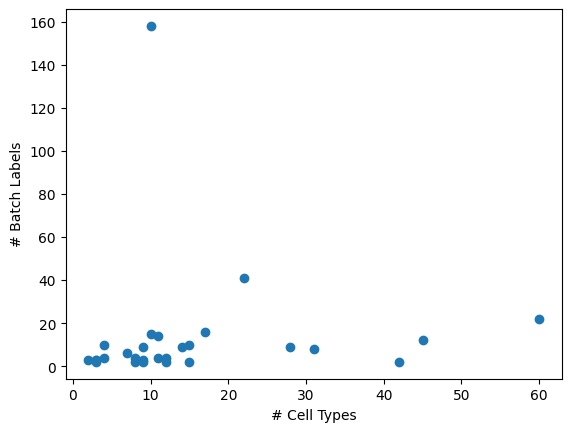

In [14]:
plt.scatter(summary['Number of cell types'], summary['Number of batches'])
plt.xlabel("# Cell Types")
plt.ylabel("# Batch Labels")
plt.show()

## Multiomics data

In [4]:
paths = glob.glob("/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/multiome/*rna.h5ad", recursive=False)
print(paths)

['/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/multiome/neurips_bmmc_multiome_rna.h5ad', '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/multiome/human_pbmc_dogma_rna.h5ad', '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/multiome/human_pbmc_tea_rna.h5ad', '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/multiome/mouse_organogenesis_rna.h5ad', '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/multiome/mouse_cortex_rna.h5ad', '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/multiome/human_cortex_rna.h5ad', '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/multiome/human_retina_35000_rna.h5ad', '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/multiome/human_retina_6donor_rna.h5ad', '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/data/multiome/human_breast_rna.h5ad', '/ubc/cs/research/beaver/pro

In [5]:
dataset_keys = {
    "neurips_bmmc_multiome_rna": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    },

    "mouse_cortex_rna": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["DonorID"]
    },

    "human_pbmc_dogma_rna": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["stim"]
    },

    "human_pbmc_tea_rna": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["batch"]
    },

    "mouse_organogenesis_rna": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["sample"]
    },

    "human_cortex_rna": {
        "celltype_keys": ["type_updated"],
        "batch_keys": ["dataset"]
    },

    "human_breast_rna": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["donor_id"]
    },

    "human_retina_35000_rna": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["donor_id"]
    },

    "human_retina_6donor_rna": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["donor_id"]
    },

    "human_renal_cortex_rna": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["donor_id"]
    },

    "mouse_kidney_rna": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["batch"]
    }
}

In [6]:
rows = []

for path in paths:
    adata = sc.read_h5ad(path)
    name = os.path.splitext(os.path.basename(path))[0]
    print(name)
    
    celltype_keys = dataset_keys[name]["celltype_keys"]
    batch_keys    = dataset_keys[name]["batch_keys"]


    ct_key = celltype_keys[0]
    bt_key = batch_keys[0]

    n_cells = adata.n_obs
    n_genes = adata.n_vars
    n_celltypes = adata.obs[ct_key].nunique() if ct_key else None
    n_batches   = adata.obs[bt_key].nunique() if bt_key else None
    
    ent_ct = entropy_from_keys(adata, [ct_key])
    ent_bt = entropy_from_keys(adata, [bt_key])
    rare, abun = rare_abundant(adata, [ct_key])
    umi = mean_umi(adata, [bt_key])
    c = pseudobulk_corr(adata, [ct_key])
    b = pseudobulk_corr(adata, [bt_key])
    
    gini_ct = gini(adata.obs[ct_key].value_counts().to_numpy())
    gini_bt = gini(adata.obs[bt_key].value_counts().to_numpy())
    
    ct_batch_specific = batch_specific_cell_type(adata, ct_key, bt_key)
    num_batch_specific = num_batch_specific_cell_types(adata, ct_key, bt_key)
    
    rows.append({
        "Dataset": path,
        "Cell count": n_cells,
        "Number of cell types": n_celltypes,
        "Number of batches": n_batches,
        "Number of genes": n_genes,
        "Celltype keys": celltype_keys,
        "Batch keys": batch_keys,
        "Entropy_celltypes": ent_ct,
        "Entropy_batches": ent_bt,
        "Rare cell types": rare,
        "Abundant cell types": abun,
        "UMIs per batch": umi,
        "Celltype correlation": c,
        "Batch correlation": b,
        'Celltype Gini': gini_ct,
        'Batch Gini': gini_bt,
        'Batch-specific cell type proportion': ct_batch_specific,
        'Num batch-specific cell types': num_batch_specific
    })

summary = pd.DataFrame(rows)
summary

neurips_bmmc_multiome_rna


/tmp/ipykernel_210141/1443714161.py:71: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_batch = adata.obs.groupby(label_key)[batch_key].nunique()
/tmp/ipykernel_210141/1443714161.py:96: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unique_counts = adata.obs.groupby(label_key)[batch_key].nunique()


human_pbmc_dogma_rna


/tmp/ipykernel_210141/1443714161.py:71: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_batch = adata.obs.groupby(label_key)[batch_key].nunique()
/tmp/ipykernel_210141/1443714161.py:96: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unique_counts = adata.obs.groupby(label_key)[batch_key].nunique()


human_pbmc_tea_rna


...

human_renal_cortex_rna


/tmp/ipykernel_210141/1443714161.py:71: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_batch = adata.obs.groupby(label_key)[batch_key].nunique()
/tmp/ipykernel_210141/1443714161.py:96: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unique_counts = adata.obs.groupby(label_key)[batch_key].nunique()


mouse_kidney_rna


/tmp/ipykernel_210141/1443714161.py:71: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_batch = adata.obs.groupby(label_key)[batch_key].nunique()
/tmp/ipykernel_210141/1443714161.py:96: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unique_counts = adata.obs.groupby(label_key)[batch_key].nunique()


,Dataset,Cell count,Number of cell types,Number of batches,Number of genes,Celltype keys,Batch keys,Entropy_celltypes,Entropy_batches,Rare cell types,Abundant cell types,UMIs per batch,Celltype correlation,Batch correlation,Celltype Gini,Batch Gini,Batch-specific cell type proportion,Num batch-specific cell types
0,/ubc/cs/research/beaver/projects/Single-cell-i...,69249,22,13,13431,[cell_type],[batch],2.671981,2.472697,2,0,"[2638.6852506426735, 2524.852077151335, 3045.6...",0.775135,0.887265,0.497451,0.230279,0.313983,0
1,/ubc/cs/research/beaver/projects/Single-cell-i...,13763,27,2,36495,[celltype],[stim],2.202726,0.687315,15,0,"[4258.146248688353, 5427.391920508226]",0.871639,0.983146,0.745988,0.053949,0.000654,1
2,/ubc/cs/research/beaver/projects/Single-cell-i...,25517,12,4,36601,[celltype],[batch],1.969677,1.386115,4,0,"[2112.0560219567324, 2087.9130230371416, 2132....",0.870601,0.987110,0.528546,0.010179,0.000000,0
3,/ubc/cs/research/beaver/projects/Single-cell-i...,56861,37,11,32285,[celltype],[sample],3.211307,2.335926,11,0,"[10983.499234303215, 8490.776627011895, 20110....",0.942249,0.978335,0.487745,0.178246,0.683175,0
4,/ubc/cs/research/beaver/projects/Single-cell-i...,45549,15,12,30201,[celltype],[DonorID],2.448845,2.432148,2,0,"[3520.7035759096616, 3892.673122065728, 3590.6...",0.857772,0.906114,0.390627,0.178681,0.599684,0
5,/ubc/cs/research/beaver/projects/Single-cell-i...,231006,33,38,36601,[type_updated],[dataset],3.167638,3.570876,7,0,"[4997.037540701015, 4560.201919894075, 6124.85...",0.934801,0.943927,0.449402,0.202335,0.648801,0
6,/ubc/cs/research/beaver/projects/Single-cell-i...,35000,28,14,61497,[cell_type],[donor_id],2.336431,2.493024,14,1,"[12480.773800456967, 6702.834391054698, 6380.4...",0.931105,0.976651,0.712535,0.297739,0.387171,0
7,/ubc/cs/research/beaver/projects/Single-cell-i...,135441,28,6,61497,[cell_type],[donor_id],2.359483,1.739689,14,1,"[6803.107510641219, 6427.141763833794, 6632.17...",0.950934,0.986605,0.705671,0.152981,0.043214,0
8,/ubc/cs/research/beaver/projects/Single-cell-i...,51367,8,16,32330,[cell_type],[donor_id],1.831400,2.628195,0,1,"[2823.093968253968, 2625.975167785235, 3639.22...",0.916143,0.947842,0.388223,0.296517,0.000000,0
9,/ubc/cs/research/beaver/projects/Single-cell-i...,37717,33,10,30950,[cell_type],[donor_id],2.358232,2.137486,19,1,"[3589.5356758694875, 3211.041032733979, 4499.4...",0.753225,0.888050,0.747950,0.285906,0.132937,1


In [7]:
summary = summary.set_index('Dataset')

In [8]:
summary.index = summary.index.str.split('/').str[-1].str.split('.').str[0]

In [9]:
summary

,Cell count,Number of cell types,Number of batches,Number of genes,Celltype keys,Batch keys,Entropy_celltypes,Entropy_batches,Rare cell types,Abundant cell types,UMIs per batch,Celltype correlation,Batch correlation,Celltype Gini,Batch Gini,Batch-specific cell type proportion,Num batch-specific cell types
Dataset,,,,,,,,,,,,,,,,,
neurips_bmmc_multiome_rna,69249,22,13,13431,[cell_type],[batch],2.671981,2.472697,2,0,"[2638.6852506426735, 2524.852077151335, 3045.6...",0.775135,0.887265,0.497451,0.230279,0.313983,0
human_pbmc_dogma_rna,13763,27,2,36495,[celltype],[stim],2.202726,0.687315,15,0,"[4258.146248688353, 5427.391920508226]",0.871639,0.983146,0.745988,0.053949,0.000654,1
human_pbmc_tea_rna,25517,12,4,36601,[celltype],[batch],1.969677,1.386115,4,0,"[2112.0560219567324, 2087.9130230371416, 2132....",0.870601,0.987110,0.528546,0.010179,0.000000,0
mouse_organogenesis_rna,56861,37,11,32285,[celltype],[sample],3.211307,2.335926,11,0,"[10983.499234303215, 8490.776627011895, 20110....",0.942249,0.978335,0.487745,0.178246,0.683175,0
mouse_cortex_rna,45549,15,12,30201,[celltype],[DonorID],2.448845,2.432148,2,0,"[3520.7035759096616, 3892.673122065728, 3590.6...",0.857772,0.906114,0.390627,0.178681,0.599684,0
human_cortex_rna,231006,33,38,36601,[type_updated],[dataset],3.167638,3.570876,7,0,"[4997.037540701015, 4560.201919894075, 6124.85...",0.934801,0.943927,0.449402,0.202335,0.648801,0
human_retina_35000_rna,35000,28,14,61497,[cell_type],[donor_id],2.336431,2.493024,14,1,"[12480.773800456967, 6702.834391054698, 6380.4...",0.931105,0.976651,0.712535,0.297739,0.387171,0
human_retina_6donor_rna,135441,28,6,61497,[cell_type],[donor_id],2.359483,1.739689,14,1,"[6803.107510641219, 6427.141763833794, 6632.17...",0.950934,0.986605,0.705671,0.152981,0.043214,0
human_breast_rna,51367,8,16,32330,[cell_type],[donor_id],1.831400,2.628195,0,1,"[2823.093968253968, 2625.975167785235, 3639.22...",0.916143,0.947842,0.388223,0.296517,0.000000,0


In [31]:
summary.to_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/spreadsheets/dataset_multiome_summary.csv')